# KITScenes — Quickstart

The first steps with the `kitscenes` API: open the dataset, pick a scene and a frame, and read a camera image, a lidar
sweep and the ego pose. Ten minutes, one scene.

The object model is `kitscenes.open()` → `Dataset` → `Scene` (one drive of about 20 s) → `Frame` (one 10 Hz time step
of that drive). Every sensor reading belongs to a frame; nothing is read until you ask for it.

**Needs:** `kitscenes[viz]` installed as in the README (plus `jupyter`) and the example scene below in a dataset root
(`$KITSCENES_ROOT`, or set `DATASET_ROOT` below).

**The example scene.** All notebooks use one scene, `c34c778f-ad8c-0aa9-7e1a-c86a73f887c7`: val, Frankfurt, 22 s. Download it alone:

```bash
export KITSCENES_ROOT=/data/kitscenes
kitscenes download "$KITSCENES_ROOT" --scenes c34c778f-ad8c-0aa9-7e1a-c86a73f887c7 --dry-run   # what it would fetch
kitscenes download "$KITSCENES_ROOT" --scenes c34c778f-ad8c-0aa9-7e1a-c86a73f887c7
```

That is 5.8 GB: the scene with all its sensors (cameras, lidars, radars, GNSS/INS), its labels and its HD map, the HD
and SD maps of the three cities, and the DOP20 aerial tiles of its area. Most cells need nothing more. Notebook 06's
optional DINOv3 section needs `--aerial-features` as well: it adds the features of the scene's area (104 GB). Notebook 08
is about all scenes; it says what more to download. Any other scene works too: set `SCENE_ID`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

## 1. Open the dataset

`kitscenes.open(root, splits=...)` lists the scenes on disk (the downloaded zips or extracted folders); it reads no
sensor data. Without `splits` it takes every split it finds. `scene.info` comes from the scene table shipped with
the package (`kitscenes.scene_table()`): split, city, lidar generation, frame count and recording metadata (weather, light, road types, ...) of every released scene, also of
those you have not downloaded (`ds.filter(city=..., weather=...)` selects by any column). Notebook 08 draws the
whole table.

In [2]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
print(ds)
print(kitscenes.scene_table()[SCENE_ID])  # the table entry, also for a scene not on disk

Dataset(root='/data/kitscenes', splits=['val'], scenes=1)
SceneInfo(scene_id='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', split='val', city='Frankfurt', lidar='velodyne', num_frames=220, recording_week='2025-W34', time_of_day='afternoon', light='day', sun_below_horizon=False, dark=False, recording_order=779, drive=11, order_in_drive=258, rig='velodyne_2025', sd_snapshot='Frankfurt_2025-W34.osm.pbf', duration_s=21.9, distance_m=174.0, mean_speed_mps=8.0, max_speed_mps=10.0, road_motorway_share=0.0, road_arterial_share=1.0, road_local_share=0.0, road_service_share=0.0, road_unmatched_share=0.0, road_dominant='arterial', speed_limit_kph_median=50.0, weather='partly_cloudy', road_surface='dry', weather_confidence='high')


## 2. A scene

A scene is indexed by position (`ds[0]`) or by its ID (`ds["<uuid>"]`). Its timeline is `scene.timestamps_ns`: frame
`i` of every sensor belongs to `timestamps_ns[i]` (integer nanoseconds since the scene start).

In [3]:
scene = ds[SCENE_ID]
print(scene)
print(f"{scene.num_frames} frames, {scene.duration_s:.1f} s, city {scene.info.city}, lidar {scene.info.lidar}")
print("first frame times (s):", scene.timestamps_ns[:4] / 1e9)
print("split:", scene.split_info)

Scene(id='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', split='val', storage=DirStorage('/data/kitscenes/data/val/c34c778f-ad8c-0aa9-7e1a-c86a73f887c7'))
220 frames, 21.9 s, city Frankfurt, lidar velodyne
first frame times (s): [0.05198797 0.15198797 0.25198797 0.35198797]
split: SplitInfo(name='val', base='val', family='default', has_maps=True, has_labels=True, has_gnss=True, pose_frame='local_utm', aliases=('validation',))


## 3. A frame and its sensors

`scene[i]` is a `Frame`: a view of time step `i` that reads on access. `frame.sensors(kind)` lists the sensors with
data at this frame; the names are also in `kitscenes.CAMERA_NAMES`, `LIDAR_NAMES` and `RADAR_NAMES`.

In [4]:
frame = scene[min(50, len(scene) - 1)]
print(frame, f"t = {frame.t_s:.2f} s")
for kind in ("camera", "lidar", "radar"):
    print(f"{kind:7s}", frame.sensors(kind))

Frame(scene='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', index=50, t_ns=5051987968) t = 5.05 s
camera  ('camera_base_front_center', 'camera_base_front_left_rect', 'camera_base_front_right_rect', 'camera_ring_front', 'camera_ring_front_left', 'camera_ring_front_right', 'camera_ring_rear', 'camera_ring_rear_left', 'camera_ring_rear_right')
lidar   ('lidar_top', 'lidar_front', 'lidar_left', 'lidar_right', 'lidar_rear', 'lidar_corner_left', 'lidar_corner_right')
radar   ('radar_front', 'radar_left', 'radar_right')


## 4. A camera image

`frame.image(camera)` decodes the stored JPEG into an `(H, W, 3)` uint8 RGB array. The cameras are 3504 × 2272;
`reduce=4` decodes at a quarter of the size directly from the JPEG (much faster), handy for previews and training.

(568, 876, 3) uint8


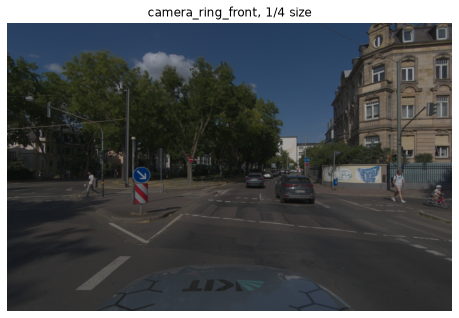

In [5]:
image = frame.image("camera_ring_front", reduce=4)
print(image.shape, image.dtype)
plt.figure(figsize=(8, 5.2))
plt.imshow(image)
plt.title("camera_ring_front, 1/4 size")
plt.axis("off")
plt.show()

## 5. A lidar sweep

`frame.lidar(name)` is a `PointCloud`: the measured points of one sweep in the vehicle's **base frame** at the frame
time (x forward, y left, z up, metres), ego-motion compensated ("deskewed"). `cloud.xyz` is (N, 3) and `cloud.attrs`
holds the other columns, one value per point. Notebook 02 shows the stored rows behind the points (`rows=True`),
notebook 03 the ground labels (`labels=True`).

PointCloud(sensor='lidar_top', n=204558, measured=204558, frame='base', t_ns=5051987968, compensated)
attributes: ['reflectivity', 'timestamp', 'ring', 'sensor_id', 'sensor_specific_data', 'row']


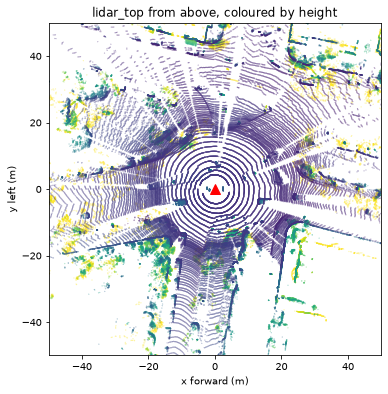

In [6]:
cloud = frame.lidar("lidar_top")
print(cloud)
print("attributes:", list(cloud.attrs))
xyz = cloud.xyz  # (N, 3) float32

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xyz[:, 0], xyz[:, 1], s=0.02, c=xyz[:, 2], cmap="viridis", vmin=-3, vmax=3)
ax.plot(0, 0, "r^", markersize=10)
ax.set(xlim=(-50, 50), ylim=(-50, 50), aspect="equal", xlabel="x forward (m)", ylabel="y left (m)",
       title="lidar_top from above, coloured by height")
plt.show()

## 6. The ego pose and the drive

`frame.pose` is the vehicle pose at the frame time (`xyz`, `quat` as qx, qy, qz, qw, and the (4, 4) `T_world_base`),
interpolated from the recorded poses. The world frame is the map's local UTM frame (in the test-e2e splits: relative
to the first pose). `frame.ego()` adds velocity, acceleration and yaw rate (`scene.ego(t_ns)` at any time), and `scene.track` holds
every recorded pose as arrays. `frame.ego()` takes central differences, which read the poses up to 0.2 s after the
frame; `frame.ego(causal=True)` uses the poses up to the frame time only, which is what a model input may see.

In [7]:
pose = frame.pose
print(pose)
state = frame.ego()
print(f"speed {state.speed:.1f} m/s, yaw rate {state.yaw_rate:.3f} rad/s")
print(f"from the past only: speed {frame.ego(causal=True).speed:.1f} m/s")
print("pose frame:", scene.pose_frame)

EgoPose(t_ns=5051987968, xyz=[ -521.3529, -1015.1191,   146.8557], quat=[ 0.002 , -0.0015,  0.3782,  0.9257])
speed 7.9 m/s, yaw rate -0.062 rad/s
from the past only: speed 8.0 m/s
pose frame: local_utm


Passing `frame="world"` gives the sweep in the world frame (through `frame.T_world_base`), so points of different
frames, the drive and the map share one coordinate system:

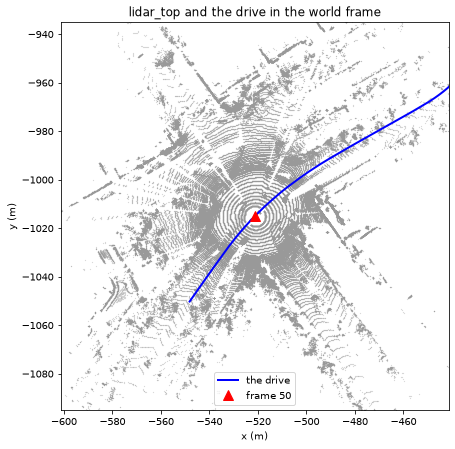

In [8]:
world = frame.lidar("lidar_top", frame="world")
drive = scene.track.xyz  # (num poses, 3)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(world.xyz[:, 0], world.xyz[:, 1], s=0.02, c="0.6")
ax.plot(drive[:, 0], drive[:, 1], "b-", linewidth=2, label="the drive")
ax.plot(*pose.xyz[:2], "r^", markersize=10, label=f"frame {frame.index}")
ax.set(xlim=(pose.xyz[0] - 80, pose.xyz[0] + 80), ylim=(pose.xyz[1] - 80, pose.xyz[1] + 80), aspect="equal",
       xlabel="x (m)", ylabel="y (m)", title="lidar_top and the drive in the world frame")
ax.legend()
plt.show()

## 7. When data is missing

Anything that can be missing (a sensor you did not download, a dropped frame, labels and maps the test splits withhold)
raises a `kitscenes.Unavailable` whose `state` says why, or returns None with `missing="none"`. `availability()` asks
first.

In [9]:
for what in ("camera_ring_front", "lidar_top", "ground_labels/lidar_top", "instances/camera_ring_rear", "map", "pose"):
    print(f"{what:28s} {frame.availability(what).value}")

try:
    frame.instances("camera_ring_front_left")  # instance masks exist for the front and rear ring cameras only
except kitscenes.Unavailable as err:
    print(f"\n{type(err).__name__} ({err.state.value}): {err}")
print(frame.instances("camera_ring_front_left", missing="none"))

camera_ring_front            present
lidar_top                    present
ground_labels/lidar_top      present
instances/camera_ring_rear   present
map                          present
pose                         present

LabelsUnavailable (not_in_release): instances/camera_ring_front_left at frame 50 is unavailable (not_in_release): the release has none for camera_ring_front_left in this scene (only for the front and rear ring cameras)
None


## Next

- `02_sensors_and_calibration.ipynb`: all cameras, lidars and radars, calibration and transforms, deskewing
- `03_labels.ipynb`: ground segmentation, instance masks, what the test splits withhold
- `04_maps.ipynb`: the HD map, map queries and map labels for learning
- `05_training.ipynb`: samples and batches for a PyTorch `DataLoader`
- `06_aerial_imagery.ipynb`: aerial orthophotos aligned with each frame
- `07_sd_maps_and_navigation.ipynb`: the OpenStreetMap road graph, routes and driving commands
- `08_dataset_overview.ipynb`: all scenes at a glance: recording conditions, the splits on the city maps